In [ ]:
!pip install transformers torch torchvision pillow

In [ ]:
from transformers import BlipProcessor, BlipForConditionalGeneration
from PIL import Image
import requests
import torch

In [ ]:
processor = BlipProcessor.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  990MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

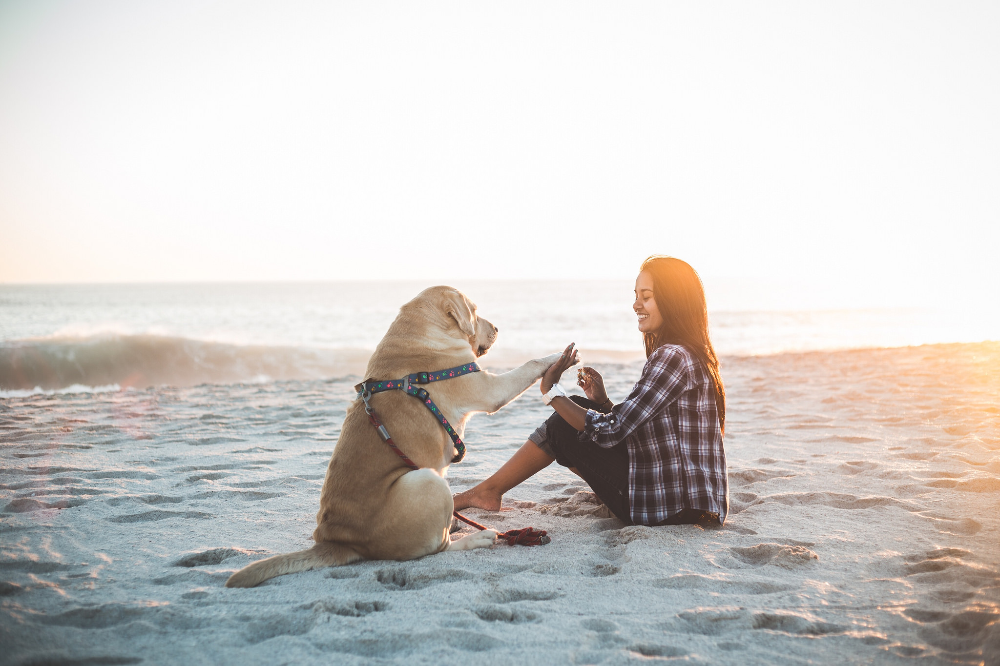

In [ ]:
url = "https://storage.googleapis.com/sfr-vision-language-research/BLIP/demo.jpg"

image = Image.open(requests.get(url, stream=True).raw).convert("RGB")

image

In [ ]:
inputs = processor(images=image, return_tensors="pt")

In [ ]:
with torch.no_grad():
    output = model.generate(**inputs, max_new_tokens=30)

In [ ]:
caption = processor.decode(output[0], skip_special_tokens=True)

print(caption)

a woman sitting on the beach with her dog


In [ ]:
def generate_caption(image):
    inputs = processor(images=image, return_tensors="pt")

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=30
        )

    caption = processor.decode(
        output[0],
        skip_special_tokens=True
    )

    return caption

In [ ]:
caption = generate_caption(image)
print(caption)

a woman sitting on the beach with her dog


In [ ]:
!pip install gradio

In [ ]:
import gradio as gr

demo = gr.Interface(
    fn=generate_caption,
    inputs=gr.Image(type="pil"),
    outputs=gr.Textbox(label="Caption"),
    title="Image Captioning with BLIP",
    description="Upload an image and generate a caption."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8b1c3dde7fa9e5e35a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
def load_image_from_url(url):
    response = requests.get(url, stream=True)
    image = Image.open(response.raw).convert("RGB")
    return image

def caption_from_url(url):
    image = load_image_from_url(url)
    return generate_caption(image)

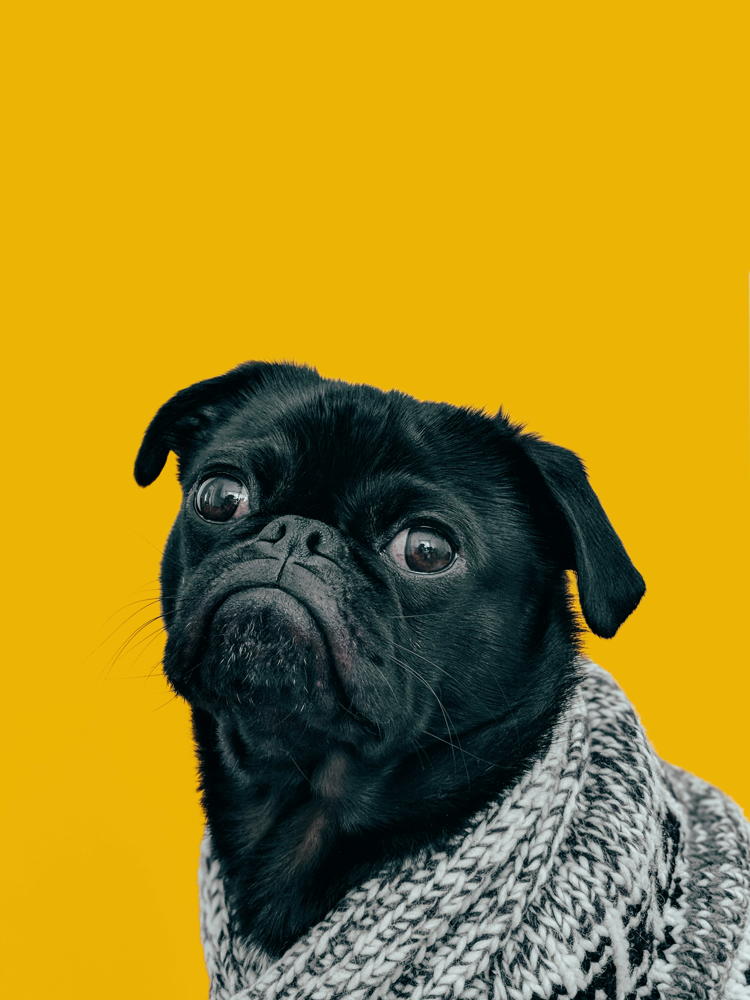

In [ ]:
url = "https://images.unsplash.com/photo-1517849845537-4d257902454a"
image = load_image_from_url(url)

image

In [ ]:
caption_from_url(url)

'a black pug dog wearing a scarf'

In [ ]:
import gradio as gr

def caption_uploaded_image(image):
    return generate_caption(image)


def caption_image_url(url):
    return caption_from_url(url)


with gr.Blocks() as demo:

    gr.Markdown("# 🖼️ Image Captioning with BLIP")
    gr.Markdown("Generate a description of an image using BLIP.")

    with gr.Tab("Upload Image"):
        image_input = gr.Image(type="pil")
        upload_button = gr.Button("Generate Caption")
        upload_output = gr.Textbox(label="Caption")

        upload_button.click(
            fn=caption_uploaded_image,
            inputs=image_input,
            outputs=upload_output
        )

    with gr.Tab("Image URL"):
        url_input = gr.Textbox(
            label="Image URL",
            placeholder="Paste an image URL here..."
        )
        url_button = gr.Button("Generate Caption")
        url_output = gr.Textbox(label="Caption")

        url_button.click(
            fn=caption_image_url,
            inputs=url_input,
            outputs=url_output
        )


demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://551c6542579e7255dc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
